# Segmentacja dachów budynków – ortofotomapa + BDOT10k (powiat wielicki)
Notebook dla Google Colab, oparty na repozytorium `przemek-kuras/bdot10k_bldg_segment`.

**Przed startem:** *Środowisko wykonawcze → Zmień typ środowiska wykonawczego → GPU T4*.

Kroki odpowiadają instrukcji z zajęć (3–17), a na końcu jest sekcja pracy samodzielnej.

## 3. Sprawdzenie GPU

In [ ]:
import torch
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA: True
GPU: Tesla T4


## 4. Pobranie repozytorium

In [ ]:
!git clone https://github.com/przemek-kuras/bdot10k_bldg_segment.git
%cd bdot10k_bldg_segment

Cloning into 'bdot10k_bldg_segment'...
remote: Enumerating objects: 35, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 35 (delta 5), reused 30 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (35/35), 25.79 KiB | 6.45 MiB/s, done.
Resolving deltas: 100% (5/5), done.
/content/bdot10k_bldg_segment


## 5–6. Katalog `data` i import danych
Wgraj do Google Drive (np. folder `MyDrive/bdot_data/`) dwa pliki:
- `83139_1483405_M-34-77-A-a-2-1.tif`
- `bdot10k_budynki_powiat_wielicki.gpkg`

(Alternatywa: wgraj je ręcznie do `data/` w panelu plików po lewej.)

In [ ]:
DRIVE_DIR = "/content/drive/MyDrive/Colab Notebooks/proj3/data"   # <- zmień, jeśli pliki są gdzie indziej

import os, shutil
os.makedirs("data", exist_ok=True)
for f in ["83139_1483405_M-34-77-A-a-2-1.tif", "bdot10k_budynki_powiat_wielicki.gpkg"]:
    src = os.path.join(DRIVE_DIR, f)
    if os.path.exists(src):
        shutil.copy(src, "data/" + f)
    else:
        print("Brak w Drive:", src, "- wgraj ręcznie do data/")
!ls -lh data

total 1.2G
-rw------- 1 root root 1.2G Nov 15 18:19 83139_1483405_M-34-77-A-a-2-1.tif
-rw------- 1 root root  37M Nov 15 18:20 bdot10k_budynki_powiat_wielicki.gpkg


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 7. Podgląd danych (zamiast QGIS: szybka kontrola w notebooku)

In [ ]:
import rasterio, geopandas as gpd
TIF  = "data/83139_1483405_M-34-77-A-a-2-1.tif"
GPKG = "data/bdot10k_budynki_powiat_wielicki.gpkg"

with rasterio.open(TIF) as src:
    print("Raster:", src.width, "x", src.height, "px | pasma:", src.count, "| CRS:", src.crs)
    print("Rozdzielczość:", src.res, "| bounds:", src.bounds, "| nodata:", src.nodata)
    bounds = src.bounds

bud = gpd.read_file(GPKG)
print("Budynki w całym powiecie:", len(bud), "| CRS:", bud.crs)
from shapely.geometry import box
bud_local = bud[bud.intersects(box(*bounds))]
print("Budynki na obszarze ortofoto:", len(bud_local))

Raster: 45455 x 46959 px | pasma: 3 | CRS: EPSG:2180
Rozdzielczość: (0.05, 0.05) | bounds: BoundingBox(left=576122.65, bottom=235193.49999999997, right=578395.4, top=237541.44999999998) | nodata: None
Budynki w całym powiecie: 70435 | CRS: EPSG:2180
Budynki na obszarze ortofoto: 3334


## 8. Konfiguracja (`configs/config.yaml`)
Zmieniamy `num_workers: 2` (zalecane w Colabie). Ścieżki do danych są już ustawione.

In [ ]:
import yaml
with open("configs/config.yaml") as f:
    cfg = yaml.safe_load(f)

cfg["orthophotos"] = ["data/83139_1483405_M-34-77-A-a-2-1.tif"]
cfg["buildings_vector"] = "data/bdot10k_budynki_powiat_wielicki.gpkg"
cfg["output_dir"] = "outputs/bdot_roofs"
cfg["training"]["num_workers"] = 2

with open("configs/config.yaml", "w") as f:
    yaml.safe_dump(cfg, f, sort_keys=False, allow_unicode=True)
print(open("configs/config.yaml").read())

orthophotos:
- data/83139_1483405_M-34-77-A-a-2-1.tif
buildings_vector: data/bdot10k_budynki_powiat_wielicki.gpkg
buildings_layer: null
output_dir: outputs/bdot_roofs
bands:
- 1
- 2
- 3
tile_size: 512
stride: 512
min_building_pixels: 12
mask_erosion_m: 0.0
all_touched: false
validation_fraction: 0.15
test_fraction: 0.15
random_seed: 42
training:
  epochs: 15
  batch_size: 8
  learning_rate: 0.0003
  weight_decay: 0.0001
  num_workers: 2
  amp: true
  patience: 8
  threshold: 0.5
  encoder_name: resnet34
  encoder_weights: imagenet
prediction:
  threshold: 0.5
  batch_size: 8
  min_polygon_area_m2: 4.0
  simplify_tolerance_m: 0.1



## 9–10. Instalacja bibliotek
Jeśli Colab zgłosi konflikt `numpy` – uruchom ponownie środowisko (*Uruchom ponownie sesję*) i wykonaj komórki od `%cd` dalej.

In [ ]:
!pip install -q -r requirements.txt

## 11. Przygotowanie danych (kafle + maski + `splits.csv`)

In [ ]:
!python -m src.prepare_data --config configs/config.yaml

83139_1483405_M-34-77-A-a-2-1.tif: 100% 91/91 [08:24<00:00,  5.55s/it]
split
test     1212
train    5596
val      1200
Created 8008 tiles in outputs/bdot_roofs/tiles


## 12. Przegląd wyniku przygotowania danych

       kafle  piksele_budynkow
split                         
test    1212          22857531
train   5596         115851231
val     1200          23892955


,image,mask,raster,row,col,split,positive_pixels
0,outputs/bdot_roofs/tiles/images/83139_1483405_...,outputs/bdot_roofs/tiles/masks/83139_1483405_M...,data/83139_1483405_M-34-77-A-a-2-1.tif,0,0,train,0
1,outputs/bdot_roofs/tiles/images/83139_1483405_...,outputs/bdot_roofs/tiles/masks/83139_1483405_M...,data/83139_1483405_M-34-77-A-a-2-1.tif,0,512,train,0
2,outputs/bdot_roofs/tiles/images/83139_1483405_...,outputs/bdot_roofs/tiles/masks/83139_1483405_M...,data/83139_1483405_M-34-77-A-a-2-1.tif,0,1024,train,0
3,outputs/bdot_roofs/tiles/images/83139_1483405_...,outputs/bdot_roofs/tiles/masks/83139_1483405_M...,data/83139_1483405_M-34-77-A-a-2-1.tif,0,1536,train,25901
4,outputs/bdot_roofs/tiles/images/83139_1483405_...,outputs/bdot_roofs/tiles/masks/83139_1483405_M...,data/83139_1483405_M-34-77-A-a-2-1.tif,0,2048,train,3132


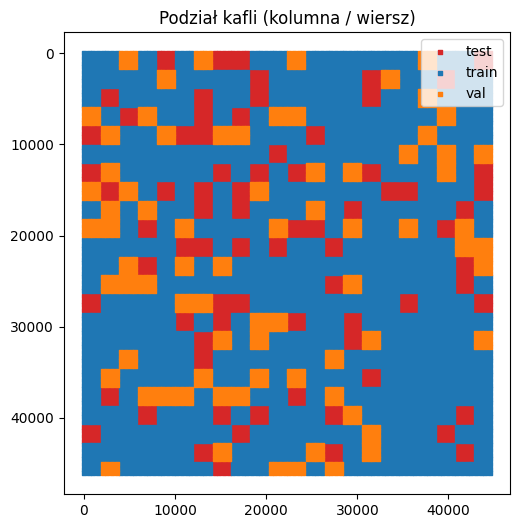

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
OUT = "outputs/bdot_roofs"
df = pd.read_csv(f"{OUT}/splits.csv")
print(df.groupby("split").agg(kafle=("image", "size"), piksele_budynkow=("positive_pixels", "sum")))
display(df.head())

# podział przestrzenny: położenie kafli wg splitu
colors = {"train": "tab:blue", "val": "tab:orange", "test": "tab:red"}
fig, ax = plt.subplots(figsize=(6, 6))
for s, g in df.groupby("split"):
    ax.scatter(g["col"], g["row"], s=12, c=colors.get(s, "gray"), label=s, marker="s")
ax.invert_yaxis(); ax.set_aspect("equal"); ax.legend(); ax.set_title("Podział kafli (kolumna / wiersz)")
plt.show()

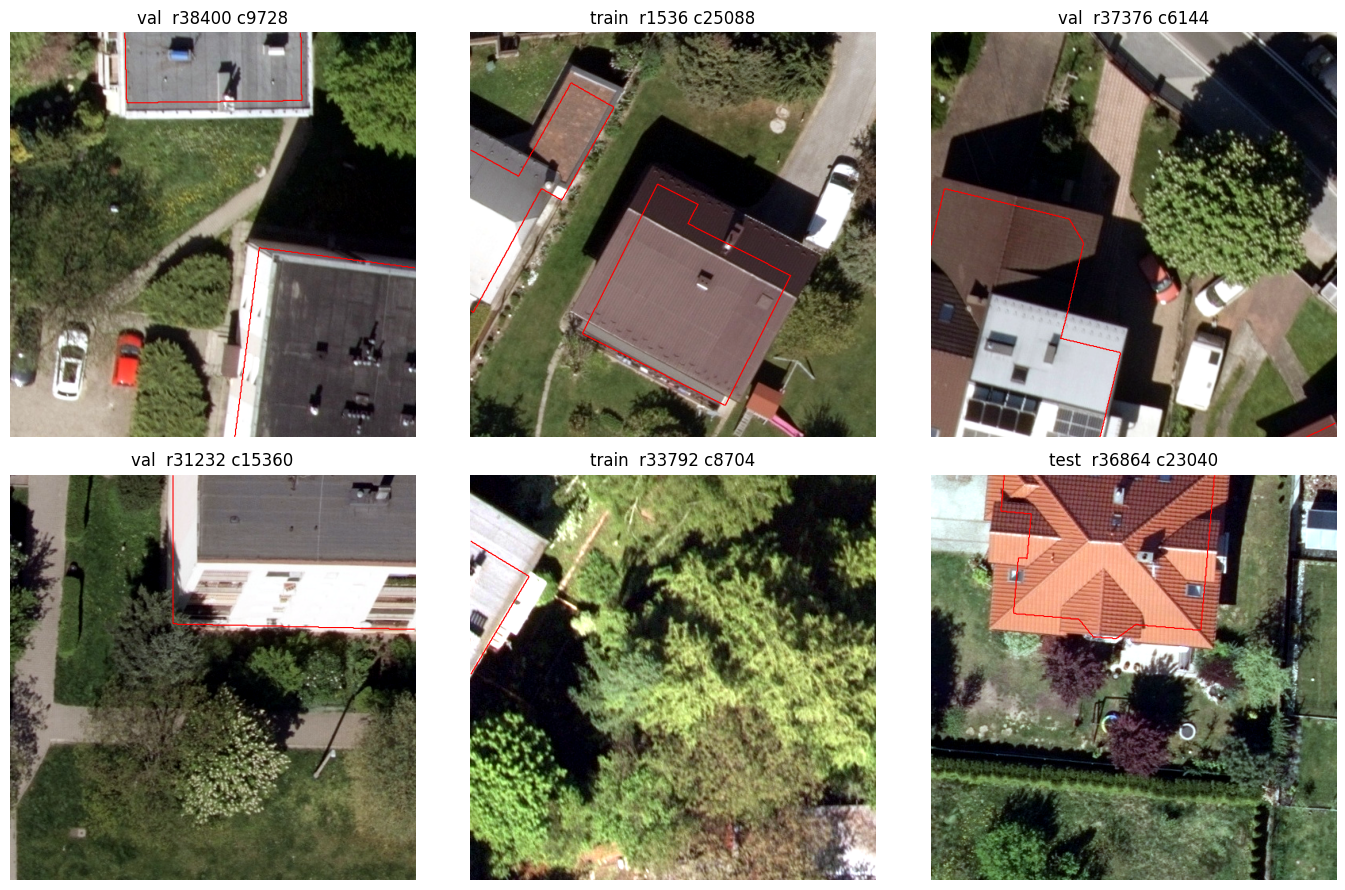

In [ ]:
# kontrola jakości: kilka kafli z maską nałożoną na obraz (patrz uwaga o przesunięciu BDOT vs dach)
sample = df[df.positive_pixels > 0].sample(min(6, (df.positive_pixels > 0).sum()), random_state=0)
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    img, m = np.load(r["image"]), np.load(r["mask"])
    ax.imshow(img); ax.contour(m, levels=[0.5], colors="red", linewidths=0.8)
    ax.set_title(f"{r['split']}  r{r['row']} c{r['col']}"); ax.axis("off")
plt.tight_layout(); plt.show()

## 13. Trenowanie (kilkanaście minut)

In [ ]:
!python -m src.train --config configs/config.yaml

Device: cuda
config.json: 100% 156/156 [00:00<00:00, 667kB/s]

model.safetensors: downloading bytes:  86% 74.8M/87.3M [00:00<00:00, 116MB/s, 5.30MB/s  ] 
model.safetensors: downloading bytes: 100% 80.6M/80.6M [00:01<00:00, 74.2MB/s, 7.75MB/s  ]
model.safetensors: reconstructing file: 100% 87.3M/87.3M [00:01<00:00, 80.3MB/s, 8.52MB/s  ]
{"epoch": 1, "train_loss": 0.44132042191043935, "val_loss": 0.3850518927971522, "train_precision": 0.6114815168012859, "train_recall": 0.7404433190701271, "train_f1": 0.6698114991126428, "train_iou": 0.5035463064935092, "val_precision": 0.7777728180220187, "val_recall": 0.7620726695379451, "val_f1": 0.7698427000154395, "val_iou": 0.6258083483740644}
{"epoch": 2, "train_loss": 0.3937659239325888, "val_loss": 0.3707080316543579, "train_precision": 0.7250182465522756, "train_recall": 0.794030570119708, "train_f1": 0.757956744442956, "train_iou": 0.6102498838799714, "val_precision": 0.7385347947752047, "val_recall": 0.8577042061143124, "val_f1": 0.7936711175

## 14. Ocena na zbiorze testowym

In [ ]:
!python -m src.evaluate --config configs/config.yaml

{
  "precision": 0.7111988303417197,
  "recall": 0.8608603440152828,
  "f1": 0.7789056237111794,
  "iou": 0.6378750463118187,
  "test_tiles": 1212,
  "threshold": 0.5,
  "note": "Pixel-level metrics against BDOT10k-derived masks; not necessarily accuracy against true visible roof edges."
}


## 15. Metryki: `training_history.csv` i `metrics.json`

,epoch,train_loss,val_loss,train_precision,train_recall,train_f1,train_iou,val_precision,val_recall,val_f1,val_iou
0,1,0.4413,0.3851,0.6115,0.7404,0.6698,0.5035,0.7778,0.7621,0.7698,0.6258
1,2,0.3938,0.3707,0.7250,0.7940,0.7580,0.6102,0.7385,0.8577,0.7937,0.6579
2,3,0.3402,0.2887,0.6631,0.7533,0.7053,0.5448,0.6520,0.7228,0.6856,0.5216
3,4,0.2967,0.2732,0.6200,0.6785,0.6479,0.4792,0.7126,0.7056,0.7091,0.5493
4,5,0.2376,0.2278,0.6905,0.7461,0.7172,0.5591,0.6718,0.8208,0.7389,0.5859
5,6,0.2548,0.2547,0.6666,0.7334,0.6984,0.5366,0.5933,0.8595,0.7020,0.5409
6,7,0.2897,0.4332,0.6324,0.6810,0.6558,0.4879,0.4028,0.7760,0.5303,0.3608
7,8,0.2827,0.2912,0.6437,0.6794,0.6611,0.4937,0.7906,0.4261,0.5538,0.3829
8,9,0.2680,0.2666,0.6529,0.6845,0.6683,0.5019,0.5516,0.8390,0.6656,0.4988
9,10,0.2664,0.3326,0.6592,0.6845,0.6716,0.5056,0.6902,0.5532,0.6141,0.4432


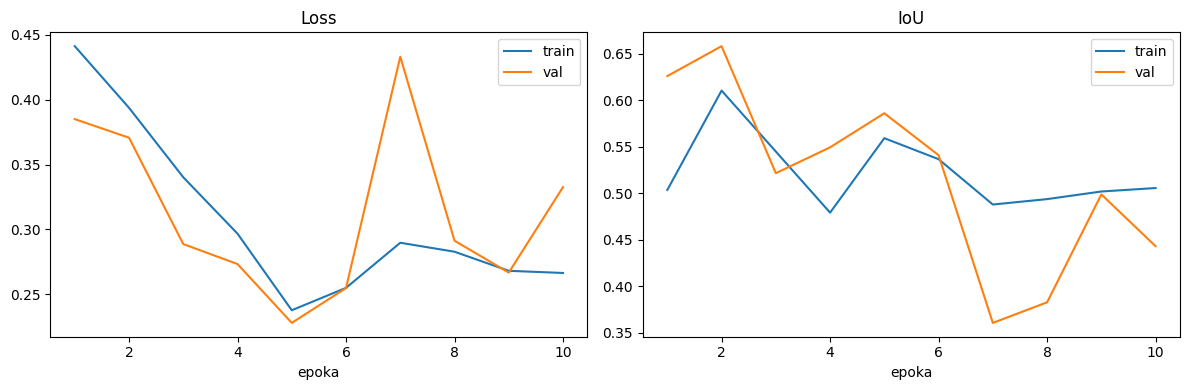

{
  "precision": 0.7111988303417197,
  "recall": 0.8608603440152828,
  "f1": 0.7789056237111794,
  "iou": 0.6378750463118187,
  "test_tiles": 1212,
  "threshold": 0.5,
  "note": "Pixel-level metrics against BDOT10k-derived masks; not necessarily accuracy against true visible roof edges."
}


In [ ]:
import json
hist = pd.read_csv(f"{OUT}/training_history.csv")
display(hist.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.epoch, hist.train_loss, label="train"); ax[0].plot(hist.epoch, hist.val_loss, label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoka"); ax[0].legend()
ax[1].plot(hist.epoch, hist.train_iou, label="train"); ax[1].plot(hist.epoch, hist.val_iou, label="val")
ax[1].set_title("IoU"); ax[1].set_xlabel("epoka"); ax[1].legend()
plt.tight_layout(); plt.show()

print(json.dumps(json.load(open(f"{OUT}/metrics.json")), indent=2, ensure_ascii=False))

## 16. Predykcja na ortofotomapie
Uwaga: ta ortofotomapa była też użyta do trenowania (podział blokowy), więc ocena wizualna na niej jest optymistyczna.
Aby sprawdzić uogólnianie, użyj innego arkusza (patrz praca samodzielna).

In [ ]:
!python -m src.predict --input data/83139_1483405_M-34-77-A-a-2-1.tif --output outputs/dachy.gpkg --config configs/config.yaml

Predicting: 100% 92/92 [06:29<00:00,  4.24s/it]
Saved 6446 polygons to outputs/dachy.gpkg


## 17. Porównanie predykcji z BDOT10k na ortofotomapie

Poligonów w predykcji: 6446 | łączna powierzchnia [m2]: 475623


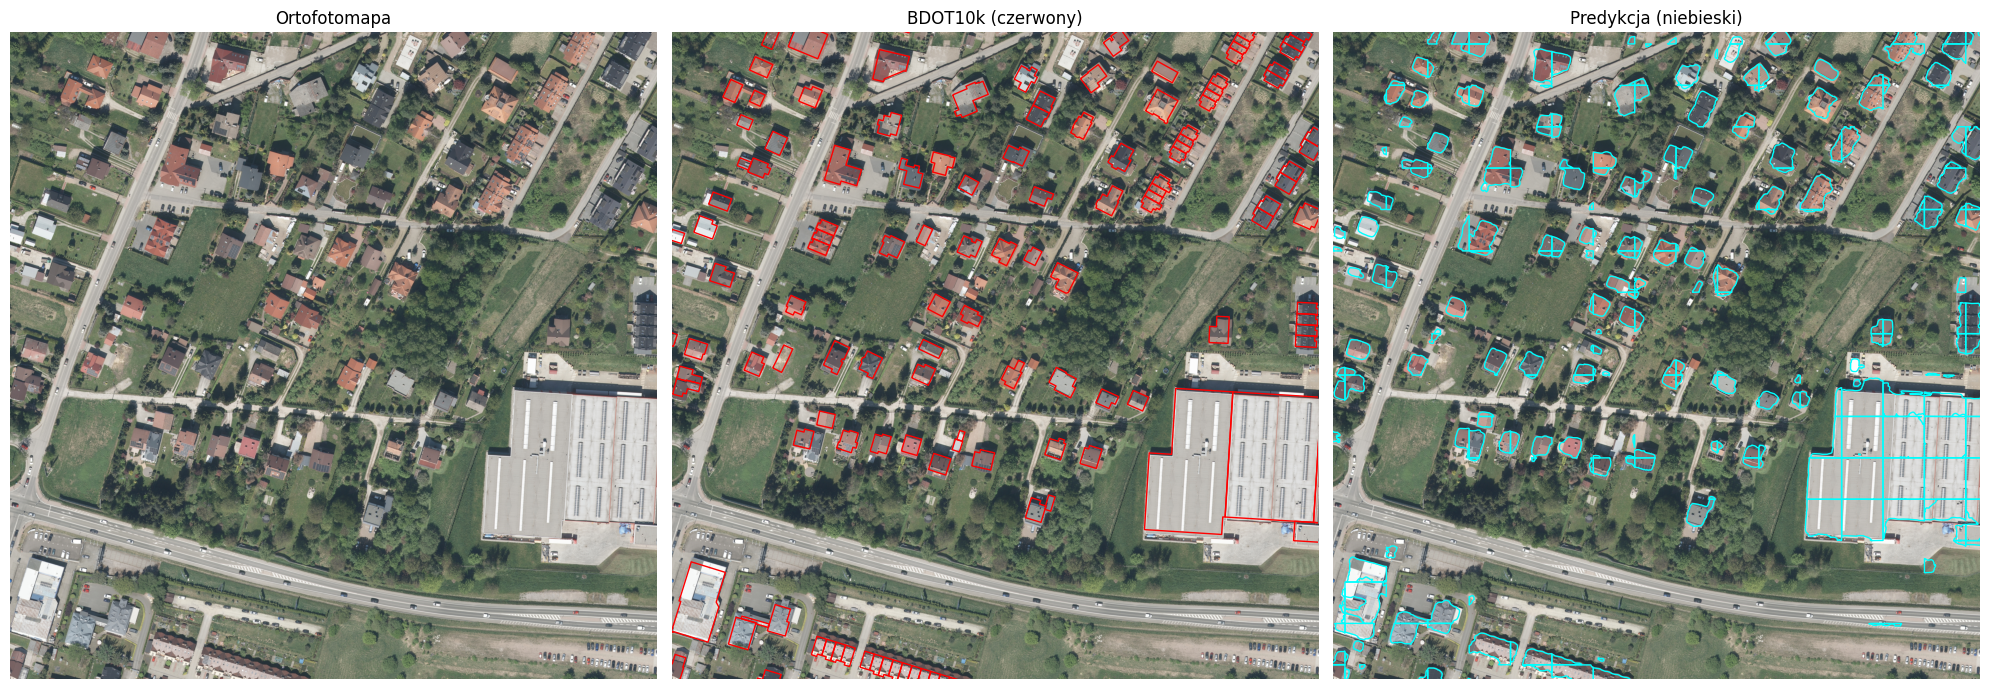

In [ ]:
import rasterio, geopandas as gpd, matplotlib.pyplot as plt
from rasterio.plot import show
from shapely.geometry import box

pred = gpd.read_file("outputs/dachy.gpkg")
print("Poligonów w predykcji:", len(pred), "| łączna powierzchnia [m2]:", round(pred.area.sum()))

with rasterio.open(TIF) as src:
    b = src.bounds
    # fragment 400 x 400 m z lewego górnego rogu – zmień X0/Y0, by przesunąć okno
    X0, Y0, W = b.left + 300, b.top - 700, 400
    win_box = box(X0, Y0, X0 + W, Y0 + W)
    from rasterio.windows import from_bounds
    win = from_bounds(X0, Y0, X0 + W, Y0 + W, src.transform)
    img = src.read([1, 2, 3], window=win)
    extent = (X0, X0 + W, Y0, Y0 + W)

bud_crs = bud_local.to_crs(pred.crs)
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, title in zip(axes, ["Ortofotomapa", "BDOT10k (czerwony)", "Predykcja (niebieski)"]):
    ax.imshow(img.transpose(1, 2, 0), extent=extent); ax.set_title(title); ax.axis("off")
bud_crs[bud_crs.intersects(win_box)].boundary.plot(ax=axes[1], color="red", linewidth=1)
pred[pred.intersects(win_box)].boundary.plot(ax=axes[2], color="cyan", linewidth=1)
for ax in axes: ax.set_xlim(X0, X0 + W); ax.set_ylim(Y0, Y0 + W)
plt.tight_layout(); plt.show()

In [ ]:
# Pobranie wyniku do QGIS
from google.colab import files
files.download("outputs/dachy.gpkg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Praca samodzielna
Poniżej gotowe punkty wyjścia. Każdy eksperyment zapisuje wyniki do osobnego `output_dir`, żeby można je było porównać.
Zmieniaj jedną rzecz naraz i zapisuj wnioski w tabeli na końcu.

### A. Funkcja pomocnicza do eksperymentów
Tworzy osobny config i uruchamia pipeline (prepare → train → evaluate), a na końcu zwraca metryki.

In [ ]:
import yaml, json, subprocess, copy

def run_experiment(name, **overrides):
    """overrides: klucze główne (tile_size, stride, mask_erosion_m, all_touched)
    oraz training__epochs, training__threshold itd. (podwójne podkreślenie = zagnieżdżenie)."""
    with open("configs/config.yaml") as f:
        c = yaml.safe_load(f)
    c = copy.deepcopy(c)
    c["output_dir"] = f"outputs/{name}"
    for k, v in overrides.items():
        if "__" in k:
            a, b = k.split("__"); c[a][b] = v
        else:
            c[k] = v
    path = f"configs/{name}.yaml"
    with open(path, "w") as f:
        yaml.safe_dump(c, f, sort_keys=False)
    for step in ["prepare_data", "train", "evaluate"]:
        r = subprocess.run(["python", "-m", f"src.{step}", "--config", path], capture_output=True, text=True)
        if r.returncode != 0:
            print(r.stdout[-1500:], r.stderr[-1500:]); raise RuntimeError(f"{step} failed")
    m = json.load(open(f"outputs/{name}/metrics.json"))
    m["experiment"] = name
    return m

results = []

### B. Erozja maski (obrys podstawy budynku w BDOT vs widoczny dach)

In [ ]:
for e in [0.25, 0.5, 1.0]:
    results.append(run_experiment(f"erosion_{e}", mask_erosion_m=e))
pd.DataFrame(results)[["experiment", "iou", "f1", "precision", "recall", "test_tiles"]]

KeyboardInterrupt: 

### C. Nakładanie kafli (`stride` < `tile_size`) – więcej kafli z jednego arkusza

In [ ]:
results.append(run_experiment("stride_384", stride=384))
pd.DataFrame(results)[["experiment", "iou", "f1", "precision", "recall", "test_tiles"]]

 21 [02:00<13:34,  7.75s/it]
83139_1483405_M-34-77-A-a-2-1.tif:  19%|█▉        | 23/121 [03:00<12:48,  7.84s/it]
Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/content/bdot10k_bldg_segment/src/prepare_data.py", line 157, in <module>
    main()
    ~~~~^^
  File "/content/bdot10k_bldg_segment/src/prepare_data.py", line 111, in main
    np.save(mp, mask.astype(np.uint8))
    ~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/numpy/lib/_npyio_impl.py", line 572, in save
    format.write_array(fid, arr, allow_pickle=allow_pickle)
    ~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/numpy/lib/_format_impl.py", line 772, in write_array
    array.tofile(fp)
    ~~~~~~~~~~~~^^^^
OSError: 262144 requested and 81792 written



RuntimeError: prepare_data failed

### D. Rozmiar kafli

In [ ]:
results.append(run_experiment("tile_256", tile_size=256, stride=256))
pd.DataFrame(results)[["experiment", "iou", "f1", "precision", "recall", "test_tiles"]]

### E. Augmentacje (`src/dataset.py`)
Repo ma już flipy, rotacje o 90° i lekką zmianę jasności. Poniżej rozszerzenie o kontrast, szum i korektę gamma.
Zmiana nadpisuje plik `src/dataset.py` (oryginał trafia do `src/dataset_orig.py`).

In [ ]:
import shutil
shutil.copy("src/dataset.py", "src/dataset_orig.py")

new_dataset = '''import numpy as np
import torch
from torch.utils.data import Dataset

class TileDataset(Dataset):
    def __init__(self, frame, augment=False):
        self.frame = frame.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        x = np.load(row["image"]).astype(np.float32)  # H,W,C in [0,1]
        y = np.load(row["mask"]).astype(np.float32)
        if self.augment:
            if np.random.rand() < 0.5:
                x, y = x[:, ::-1].copy(), y[:, ::-1].copy()
            if np.random.rand() < 0.5:
                x, y = x[::-1, :].copy(), y[::-1, :].copy()
            k = np.random.randint(0, 4)
            x, y = np.rot90(x, k).copy(), np.rot90(y, k).copy()
            # jasność / kontrast
            if np.random.rand() < 0.5:
                x = np.clip((x - 0.5) * np.random.uniform(0.8, 1.2) + 0.5
                            + np.random.uniform(-0.05, 0.05), 0, 1)
            # gamma
            if np.random.rand() < 0.3:
                x = np.clip(x, 0, 1) ** np.random.uniform(0.8, 1.25)
            # szum gaussowski
            if np.random.rand() < 0.3:
                x = np.clip(x + np.random.normal(0, 0.02, x.shape), 0, 1)
            # losowe przesunięcie kanałów (symulacja różnic w barwie)
            if np.random.rand() < 0.2:
                x = np.clip(x * np.random.uniform(0.95, 1.05, size=(1, 1, x.shape[2])), 0, 1)
            x = x.astype(np.float32)
        x = torch.from_numpy(np.moveaxis(x, -1, 0).copy()).float()
        y = torch.from_numpy(y[None, ...].copy()).float()
        return x, y
'''
open("src/dataset.py", "w").write(new_dataset)

results.append(run_experiment("augment_extended"))
pd.DataFrame(results)[["experiment", "iou", "f1", "precision", "recall", "test_tiles"]]

### F. Inny próg i więcej epok

In [ ]:
results.append(run_experiment("epochs_30_thr04", training__epochs=30, training__threshold=0.4))
pd.DataFrame(results)[["experiment", "iou", "f1", "precision", "recall", "test_tiles"]]

### G. Podsumowanie eksperymentów
Zestaw wyniki w tabeli i opisz wnioski:
- która erozja maski poprawiła IoU i czy zgadza się to z oceną wizualną?
- czy nakładanie kafli lub augmentacje pomogły, czy tylko wydłużyły trening?
- jak wypada precyzja vs czułość (czy model nadmiernie wykrywa budynki, np. parkingi i drogi)?
- ograniczenia: BDOT10k to obrys podstawy, a nie dachu; jeden arkusz = zbiór testowy z tego samego obszaru.

In [ ]:
summary = pd.DataFrame(results)[["experiment", "iou", "f1", "precision", "recall", "test_tiles"]].round(4)
display(summary)
summary.plot.bar(x="experiment", y=["iou", "f1"], figsize=(10, 4)); plt.xticks(rotation=30, ha="right"); plt.show()